# Анализ модели DreamRecFMText

Архитектура DreamRecText (frozen TEM-эмбеддинги, SASRec-энкодер, concat-денойзер `Linear(3d, d)`), генеративный процесс — Flow Matching: сеть предсказывает velocity `u = z₁ − z₀`, сэмплинг — Euler ODE от шума `z₀` к эмбеддингу товара `z₁`.

Архитектура (`d_emb`, `d_ff`, …) читается из чекпойнта; из конфига берутся только `n_heads`, `dropout` и настройки eval. Секция 1 воспроизводит протокол тренера: пересчитанный val должен совпасть с метриками в чекпойнте — это проверка корректной загрузки.

In [1]:
import sys, os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
sys.path.append('../src')

import csv
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import yaml

from models.dreamrec_fm_text import DreamRecFMText
from data import build_dataloaders
from evaluate import evaluate

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

In [2]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
CKPT_DIR    = '../checkpoints/dreamrec_fm_text'
CONFIG_PATH = '../configs/dreamrec_fm_text.yaml'   # только n_heads, dropout и eval-настройки
DATA_DIR    = '../data/ATG'
N_ITEMS     = 11924
PADDING     = 11924
N_SAMPLES   = 1000   # сколько примеров усреднять в трекинге траектории
BATCH_SIZE  = 256    # для анализа; протокол тренера использует batch_size из конфига
SEED        = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [ ]:
# ════════════════════════════════════════════════════════════
# Чекпойнт и модель
# ════════════════════════════════════════════════════════════
ckpt_path = Path(CKPT_DIR) / 'best.pt'
if not ckpt_path.exists():
    ckpt_path = Path(CKPT_DIR) / 'latest.pt'
print(f'Checkpoint: {ckpt_path}')

# На CPU через mmap: в чекпойнте лежит и состояние Adam (у 3072d это ~2 ГБ),
# на GPU переносим только модель.
ckpt = torch.load(ckpt_path, map_location='cpu', mmap=True)
sd   = ckpt['model_state']
mcfg = ckpt.get('model_cfg', {})
print(f'epoch={ckpt.get("epoch")}, metrics={ckpt.get("metrics")}')
print(f'model_cfg={mcfg}')

# В коде денойзер только линейный: чекпойнты с mlp-денойзером (dreamrec_fm_text_1) не загрузить.
assert 'denoiser.2.weight' not in sd, 'чекпойнт с mlp-денойзером — этот вариант удалён из DreamRecFMText'

with open(CONFIG_PATH) as f:
    cfg_yaml = yaml.safe_load(f)
m_yaml = cfg_yaml.get('model', {})
d_yaml = cfg_yaml.get('data', {})
ev     = cfg_yaml.get('eval', {})

NUM_SAMPLE_STEPS = 50
W_CFG            = float(mcfg.get('w_cfg', 0.0))
TRAIN_BATCH_SIZE = int(d_yaml.get('batch_size', 1024))

# Архитектура — из state_dict. Эмбеддинги товаров и whitening-буферы уже лежат
# в чекпойнте, поэтому PCA не пересчитываем и общий whitening_cache.npz не трогаем.
D_EMB       = sd['item_embedding.weight'].shape[1]
D_FF        = sd['encoder_block.ff.0.weight'].shape[0]
MAX_SEQ_LEN = sd['pos_embedding.weight'].shape[0]
# n_heads в чекпойнт не сохраняется, а форма весов от него не зависит — берём из yaml.
# Правильность проверяет секция 1: пересчитанный val должен совпасть с чекпойнтом.
N_HEADS     = int(m_yaml.get('n_heads', 4))
print(f'd_emb={D_EMB}, d_ff={D_FF}, n_heads={N_HEADS} (из yaml)')
print(f'w_cfg={W_CFG}, num_sample_steps={NUM_SAMPLE_STEPS}')

model = DreamRecFMText(
    item_embeddings_raw=np.zeros((N_ITEMS, D_EMB), dtype=np.float32),
    padding_idx=PADDING,
    use_pca=False,
    n_heads=N_HEADS,
    d_ff=D_FF,
    dropout=float(m_yaml.get('dropout', 0.1)),
    max_seq_len=MAX_SEQ_LEN,
    p_uncond=float(mcfg.get('p_uncond', 0.0)),
    w_cfg=W_CFG,
    retrieval_metric=str(mcfg.get('retrieval_metric', 'cosine')),
)
missing, unexpected = model.load_state_dict(sd, strict=False)
assert not missing and set(unexpected) <= {'whitening_mu', 'whitening_V', 'whitening_scale'}, \
    f'state_dict mismatch: missing={missing}, unexpected={unexpected}'
model = model.to(device)

ema_shadow = ckpt.get('ema_shadow', {})
if ema_shadow:
    for name, param in model.named_parameters():
        if name in ema_shadow:
            param.data.copy_(ema_shadow[name].to(device))
    print('EMA weights loaded')

model.eval()
summary = model.param_summary()
print(f'Trainable: {summary["total_trainable"]:,}, Frozen: {summary["total_frozen"]:,}')
print('Model ready')

In [4]:
loaders = build_dataloaders(data_dir=DATA_DIR, batch_size=BATCH_SIZE,
                            num_workers=0, splits=('train', 'val', 'test'))
for split, loader in loaders.items():
    print(f'{split:5s}: {len(loader.dataset):,} sequences')

train: 15,529 sequences
val  : 1,941 sequences
test : 1,942 sequences


## 1. Метрики по протоколу тренера

Ровно как финальный тест в `train_dreamrec_fm_text.py`: `evaluate()` с `seed=42`, тем же `batch_size` и ретривалом из чекпойнта. Строка «val (пересчёт)» должна совпасть с «val (чекпойнт)».

In [5]:
# ════════════════════════════════════════════════════════════
# Метрики по протоколу тренера
# ════════════════════════════════════════════════════════════
# От batch_size зависит, как режется поток случайного шума при сэмплинге,
# поэтому для точного совпадения берём тот же batch_size, что при обучении.
proto_loaders = build_dataloaders(data_dir=DATA_DIR, batch_size=TRAIN_BATCH_SIZE,
                                  num_workers=0, splits=('val', 'test'))

def protocol_eval(split):
    torch.manual_seed(42)
    return evaluate(model=model, dataloader=proto_loaders[split], top_k_values=(10, 20),
                    num_sample_steps=NUM_SAMPLE_STEPS, w_cfg=W_CFG, device=device,
                    show_progress=False)

val_metrics  = protocol_eval('val')
test_metrics = protocol_eval('test')

ckpt_metrics = ckpt.get('metrics', {})
print(pd.DataFrame({'val (чекпойнт)': ckpt_metrics,
                    'val (пересчёт)': val_metrics,
                    'test':           test_metrics}).T.to_string(float_format=lambda x: f'{x:.4f}'))

diff = max(abs(val_metrics[k] - ckpt_metrics[k]) for k in ckpt_metrics)
verdict = 'модель загружена корректно' if diff < 1e-3 else 'НЕ совпадает — проверь N_HEADS и CONFIG_PATH'
print(f'\nmax |val пересчёт − val чекпойнт| = {diff:.1e} → {verdict}')

                HR@10  NDCG@10  HR@20  NDCG@20
val (чекпойнт) 0.0371   0.0303 0.0448   0.0322
val (пересчёт) 0.0371   0.0303 0.0448   0.0322
test           0.0427   0.0323 0.0510   0.0344

max |val пересчёт − val чекпойнт| = 0.0e+00 → модель загружена корректно


## 2. Траектория ODE и метрики по трём ретривалам

In [ ]:
# ════════════════════════════════════════════════════════════
# Вспомогательные функции
# ════════════════════════════════════════════════════════════
W_ITEMS = model.item_embedding.weight[:N_ITEMS].detach()
METRICS = ['HR@10', 'NDCG@10', 'HR@20', 'NDCG@20']
RETRIEVALS = ['Dot Product', 'Cosine Sim', 'L2 Distance']
TRAIN_RETRIEVAL = {'dot': 'Dot Product', 'cosine': 'Cosine Sim', 'l2': 'L2 Distance'}[model.retrieval_metric]

_train_df  = pd.read_pickle(Path(DATA_DIR) / 'train_data.df')
_freq_all  = pd.Series(0, index=range(N_ITEMS)); _freq_all.update(_train_df['next'].value_counts())
_freq_vals = _freq_all.values.astype(float)
_norms     = W_ITEMS.norm(dim=-1).cpu().numpy()
_mask      = _freq_vals > 0
TRAIN_TARGET_NORM = float((_norms[_mask] * _freq_vals[_mask]).sum() / _freq_vals[_mask].sum())
print(f'E[||e_target||] по train = {TRAIN_TARGET_NORM:.3f}')
print(f'd_emb = {model.d_emb}, E[||noise||] = sqrt({model.d_emb}) = {np.sqrt(model.d_emb):.2f}')
print(f'ретривал при обучении: {TRAIN_RETRIEVAL}')


@torch.no_grad()
def oracle_for(history, mask):
    """История → oracle embedding через Euler ODE."""
    h = model.encode_history(history, mask)
    return model.sample(h, num_steps=NUM_SAMPLE_STEPS, w_cfg=W_CFG)


@torch.no_grad()
def sample_with_tracking(history, mask, target_emb):
    """Тот же Euler ODE, что model.sample, но с записью расстояний на каждом шаге."""
    B = history.shape[0]
    random_emb = W_ITEMS[torch.randint(0, N_ITEMS, (B,), device=device)]
    h = model.encode_history(history, mask)
    z = torch.randn_like(h)

    tracking = {k: [] for k in ['l2_target', 'l2_random', 'norm_x', 'cos_target', 'cos_random']}
    def record(x):
        for name, ref in [('target', target_emb), ('random', random_emb)]:
            tracking[f'l2_{name}'].append((x - ref).norm(dim=-1).mean().item())
            tracking[f'cos_{name}'].append(F.cosine_similarity(x, ref, dim=-1).mean().item())
        tracking['norm_x'].append(x.norm(dim=-1).mean().item())

    record(z)
    dt = 1.0 / NUM_SAMPLE_STEPS
    for i in range(NUM_SAMPLE_STEPS):
        tau = torch.full((B,), i * dt, device=device)
        v = model.forward(z, h, tau)
        if W_CFG != 0.0:
            v = (1.0 + W_CFG) * v - W_CFG * model.forward_uncon(z, tau)
        z = z + dt * v
        record(z)
    return tracking


def hit_ratio(rankings, targets, k):
    return (rankings[:, :k] == targets.unsqueeze(-1)).any(dim=-1).float().mean().item()


def ndcg(rankings, targets, k):
    top_k   = rankings[:, :k]
    matches = (top_k == targets.unsqueeze(-1))
    rank    = matches.float().argmax(dim=-1)
    hit     = matches.any(dim=-1)
    return (1.0 / torch.log2(rank.float() + 2.0) * hit.float()).mean().item()


def metrics_row(rankings, targets):
    return {'HR@10': hit_ratio(rankings, targets, 10), 'NDCG@10': ndcg(rankings, targets, 10),
            'HR@20': hit_ratio(rankings, targets, 20), 'NDCG@20': ndcg(rankings, targets, 20)}


def rank_by_metric(oracle, metric):
    if metric == 'Dot Product':
        return (oracle @ W_ITEMS.T).topk(20, dim=-1).indices.cpu()
    if metric == 'Cosine Sim':
        return (F.normalize(oracle, dim=-1) @ F.normalize(W_ITEMS, dim=-1).T).topk(20, dim=-1).indices.cpu()
    if metric == 'L2 Distance':
        l2_sq = (oracle.pow(2).sum(-1, keepdim=True) - 2.0 * oracle @ W_ITEMS.T
                 + W_ITEMS.pow(2).sum(-1).unsqueeze(0))
        return l2_sq.topk(20, dim=-1, largest=False).indices.cpu()
    raise ValueError(f'Unknown metric: {metric!r}')


@torch.no_grad()
def compute_metrics(loader, seed, shuffle_history=False):
    """Метрики по трём ретривалам + random + FM loss.
    shuffle_history=True — oracle строится по истории другого пользователя из батча."""
    torch.manual_seed(seed)
    ranks = {name: [] for name in RETRIEVALS + ['Random']}
    targets, total_loss = [], 0.0
    for batch in loader:
        history, mask, target = (batch[k].to(device) for k in ('history', 'mask', 'target'))
        B = history.shape[0]
        total_loss += model.compute_loss(history, target, mask).item()
        if shuffle_history:
            perm = torch.randperm(B, device=device)
            history, mask = history[perm], mask[perm]
        oracle = oracle_for(history, mask)
        for name in RETRIEVALS:
            ranks[name].append(rank_by_metric(oracle, name))
        ranks['Random'].append(torch.stack([torch.randperm(N_ITEMS)[:20] for _ in range(B)]))
        targets.append(target.cpu())
    targets = torch.cat(targets)
    rows = {name: metrics_row(torch.cat(rl), targets) for name, rl in ranks.items()}
    return rows, total_loss / len(loader)


def mean_std_table(runs, names):
    """runs: список {name: {metric: value}} → таблица 'mean ± std'."""
    table = []
    for name in names:
        row = {'Retrieval': name}
        for m in METRICS:
            vals = np.array([r[name][m] for r in runs])
            row[m] = f'{vals.mean():.4f} ± {vals.std():.4f}'
        table.append(row)
    return pd.DataFrame(table).set_index('Retrieval')


def analyze_split(loader, split_name, n_samples=N_SAMPLES, seed=SEED, n_runs=5):
    """Траектория ODE (1 раз) + метрики по трём ретривалам (n_runs прогонов, mean ± std)."""
    # ── Трекинг траектории ────────────────────────────────────
    torch.manual_seed(seed)
    acc, n_track, n_batches = None, 0, 0
    for batch in loader:
        if n_track >= n_samples:
            break
        history, mask, target = (batch[k].to(device) for k in ('history', 'mask', 'target'))
        tr = {k: np.array(v) for k, v in sample_with_tracking(history, mask, model.item_embedding(target)).items()}
        acc = tr if acc is None else {k: acc[k] + tr[k] for k in acc}
        n_track += history.shape[0]
        n_batches += 1
    acc   = {k: v / n_batches for k, v in acc.items()}
    steps = np.arange(len(acc['norm_x']))

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    ax = axes[0]
    ax.plot(steps, acc['l2_target'], color='tomato',    lw=2, label='Target item')
    ax.plot(steps, acc['l2_random'], color='steelblue', lw=2, label='Random item', ls='--')
    ax.set_title('L2 Distance', fontsize=12); ax.set_xlabel('ODE step'); ax.set_ylabel('↓ closer')
    ax.legend(fontsize=9); ax.set_xlim(0, len(steps) - 1)

    ax = axes[1]
    ax.plot(steps, acc['norm_x'], color='mediumorchid', lw=2, label='||z_τ||')
    ax.axhline(np.sqrt(model.d_emb), color='steelblue', ls='--', lw=1.2,
               label=f'E[||z_0||] = {np.sqrt(model.d_emb):.1f}')
    ax.axhline(TRAIN_TARGET_NORM, color='tomato', ls='--', lw=1.2,
               label=f'E[||e_target||] = {TRAIN_TARGET_NORM:.2f}')
    ax.set_title('Норма z_τ', fontsize=12); ax.set_xlabel('ODE step'); ax.set_ylabel('||z||')
    ax.legend(fontsize=9); ax.set_xlim(0, len(steps) - 1); ax.set_ylim(bottom=0)

    ax = axes[2]
    ax.plot(steps, acc['cos_target'], color='tomato',    lw=2, label='Target item')
    ax.plot(steps, acc['cos_random'], color='steelblue', lw=2, label='Random item', ls='--')
    ax.set_title('Cosine Similarity', fontsize=12); ax.set_xlabel('ODE step'); ax.set_ylabel('↑ closer')
    ax.legend(fontsize=9); ax.set_xlim(0, len(steps) - 1)

    plt.suptitle(f'{split_name.upper()} — DreamRecFMText ODE trajectory  '
                 f'(d_emb={model.d_emb}, steps={NUM_SAMPLE_STEPS}, '
                 f'w_cfg={W_CFG}, {n_track} samples)', fontsize=12, y=1.02)
    plt.tight_layout(); plt.show()

    # ── Метрики: n_runs прогонов с разным шумом ───────────────
    runs, losses = [], []
    for i in range(n_runs):
        print(f'  Run {i+1}/{n_runs} (seed={seed + i * 100})...', end='\r')
        rows, loss = compute_metrics(loader, seed + i * 100)
        runs.append(rows)
        losses.append(loss)
    print()
    df = mean_std_table(runs, RETRIEVALS + ['Random'])
    print(f'{split_name.capitalize()} — {n_runs} запусков, FM loss {np.mean(losses):.4f} ± {np.std(losses):.4f}\n')
    print(df.to_string())
    print()
    return df

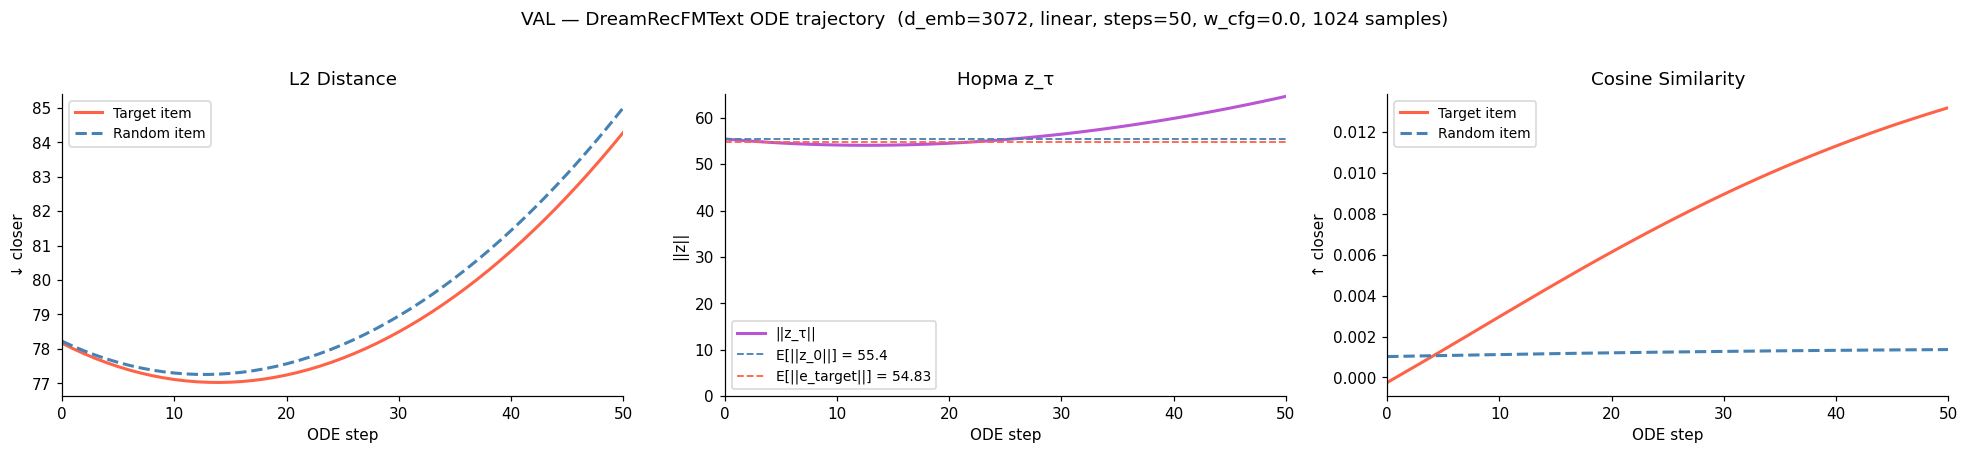

  Run 5/5 (seed=442)...
Val — 5 запусков, FM loss 2.2660 ± 0.0026

                       HR@10          NDCG@10            HR@20          NDCG@20
Retrieval                                                                      
Dot Product  0.0372 ± 0.0007  0.0285 ± 0.0010  0.0426 ± 0.0016  0.0298 ± 0.0009
Cosine Sim   0.0372 ± 0.0009  0.0294 ± 0.0010  0.0423 ± 0.0018  0.0307 ± 0.0011
L2 Distance  0.0147 ± 0.0003  0.0128 ± 0.0002  0.0163 ± 0.0007  0.0132 ± 0.0003
Random       0.0008 ± 0.0006  0.0003 ± 0.0002  0.0018 ± 0.0003  0.0005 ± 0.0001



In [7]:
val_df = analyze_split(loaders['val'], 'val')

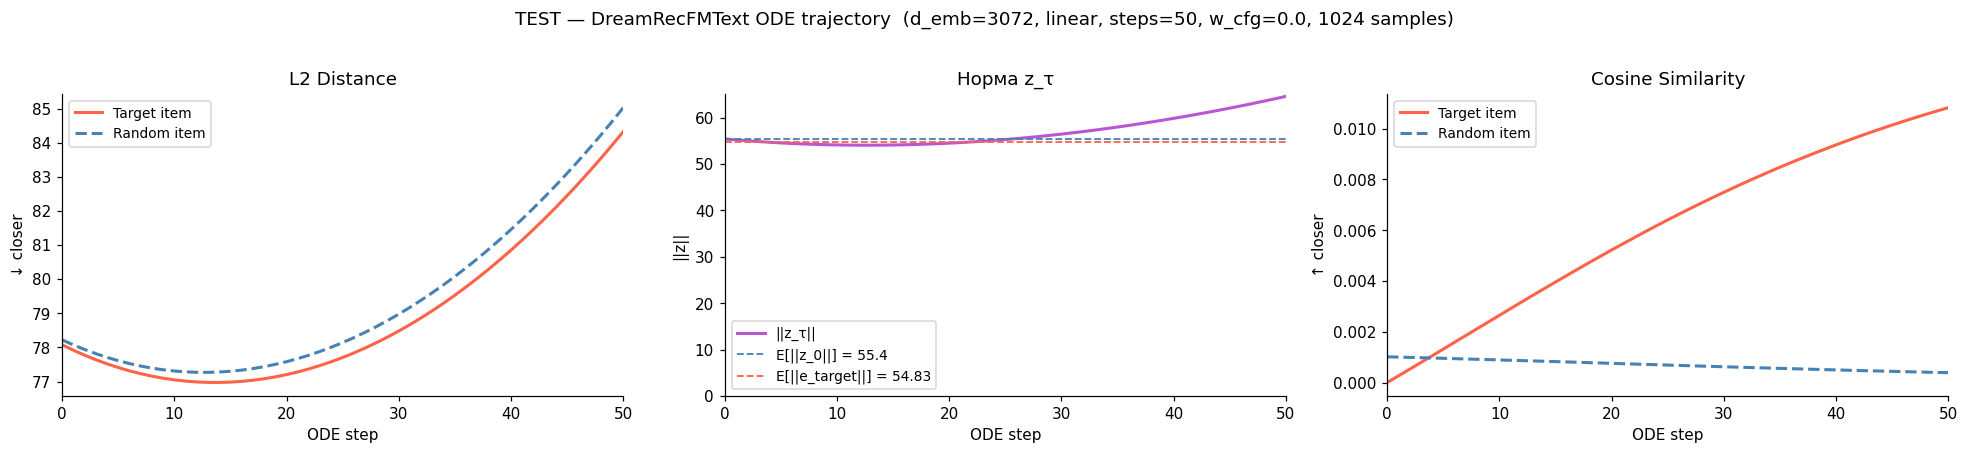

  Run 5/5 (seed=442)...
Test — 5 запусков, FM loss 2.2450 ± 0.0072

                       HR@10          NDCG@10            HR@20          NDCG@20
Retrieval                                                                      
Dot Product  0.0398 ± 0.0022  0.0308 ± 0.0011  0.0454 ± 0.0023  0.0323 ± 0.0011
Cosine Sim   0.0416 ± 0.0025  0.0320 ± 0.0011  0.0471 ± 0.0025  0.0334 ± 0.0012
L2 Distance  0.0157 ± 0.0010  0.0137 ± 0.0005  0.0171 ± 0.0006  0.0141 ± 0.0004
Random       0.0008 ± 0.0003  0.0004 ± 0.0001  0.0022 ± 0.0005  0.0007 ± 0.0002



In [8]:
test_df = analyze_split(loaders['test'], 'test')

In [9]:
# Train-сплит в ~8 раз больше val — считается заметно дольше.
# train_df = analyze_split(loaders['train'], 'train')

## 3. Модель vs шум N(0, I) vs аналитический random

=== VAL ===
                     HR@10  NDCG@10  HR@20  NDCG@20
Model (Cosine Sim)  0.0371   0.0293 0.0438   0.0310
Noise (Cosine Sim)  0.0015   0.0006 0.0041   0.0012
Random (analytical) 0.0008   0.0004 0.0017   0.0006

=== TEST ===
                     HR@10  NDCG@10  HR@20  NDCG@20
Model (Cosine Sim)  0.0448   0.0341 0.0484   0.0350
Noise (Cosine Sim)  0.0005   0.0002 0.0015   0.0005
Random (analytical) 0.0008   0.0004 0.0017   0.0006



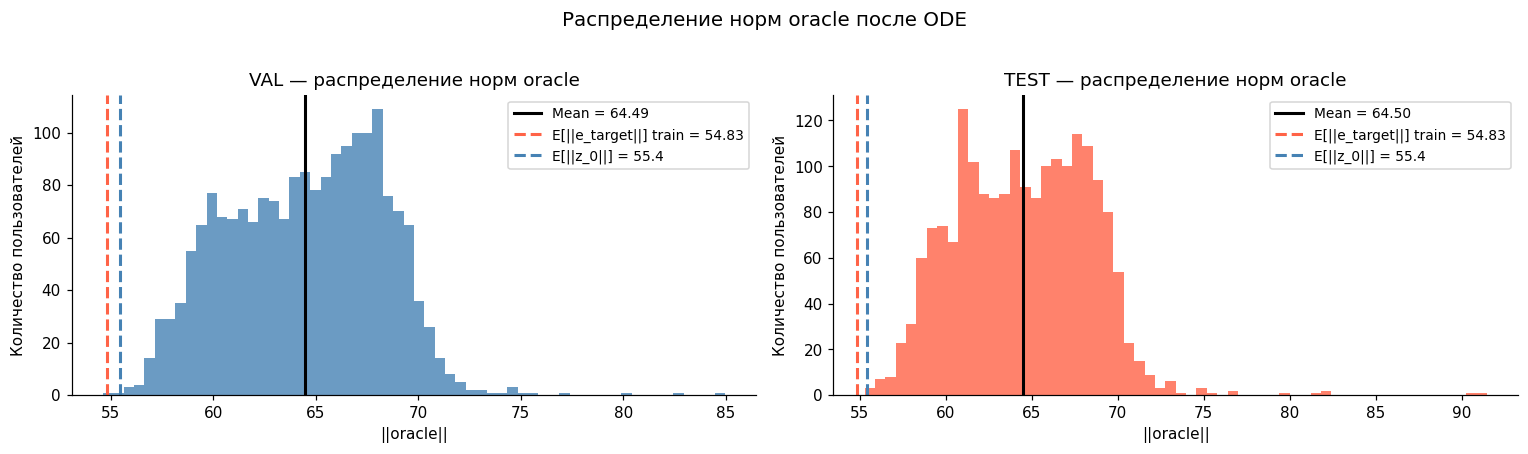

In [10]:
# ════════════════════════════════════════════════════════════
# Модель vs шум N(0, I) vs аналитический random
# ════════════════════════════════════════════════════════════
COMPARE_METRIC = TRAIN_RETRIEVAL   # тот же ретривал, что при обучении

def analytical_random(k):
    return k / N_ITEMS, sum(1.0 / np.log2(r + 2) for r in range(k)) / N_ITEMS

(hr10_rnd, ndcg10_rnd), (hr20_rnd, ndcg20_rnd) = analytical_random(10), analytical_random(20)

torch.manual_seed(SEED)
results, oracle_norms = {}, {}
for split_name in ['val', 'test']:
    r_model, r_noise, targets, norms = [], [], [], []
    with torch.no_grad():
        for batch in loaders[split_name]:
            history, mask, target = (batch[k].to(device) for k in ('history', 'mask', 'target'))
            oracle = oracle_for(history, mask)
            r_model.append(rank_by_metric(oracle, COMPARE_METRIC))
            r_noise.append(rank_by_metric(torch.randn_like(oracle), COMPARE_METRIC))
            norms.append(oracle.norm(dim=-1).cpu())
            targets.append(target.cpu())
    targets = torch.cat(targets)
    oracle_norms[split_name] = torch.cat(norms).numpy()
    results[split_name] = pd.DataFrame({
        f'Model ({COMPARE_METRIC})': metrics_row(torch.cat(r_model), targets),
        f'Noise ({COMPARE_METRIC})': metrics_row(torch.cat(r_noise), targets),
        'Random (analytical)': {'HR@10': hr10_rnd, 'NDCG@10': ndcg10_rnd,
                                'HR@20': hr20_rnd, 'NDCG@20': ndcg20_rnd},
    }).T

for split_name, df in results.items():
    print(f'=== {split_name.upper()} ===')
    print(df.to_string(float_format=lambda x: f'{x:.4f}'))
    print()

# Распределение норм oracle
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = {'val': 'steelblue', 'test': 'tomato'}
for ax, split_name in zip(axes, ['val', 'test']):
    norms_arr = oracle_norms[split_name]
    ax.hist(norms_arr, bins=60, color=colors[split_name], alpha=0.8, edgecolor='none')
    ax.axvline(norms_arr.mean(), color='black', lw=2, label=f'Mean = {norms_arr.mean():.2f}')
    ax.axvline(TRAIN_TARGET_NORM, color='tomato', lw=2, ls='--',
               label=f'E[||e_target||] train = {TRAIN_TARGET_NORM:.2f}')
    ax.axvline(np.sqrt(model.d_emb), color='steelblue', lw=2, ls='--',
               label=f'E[||z_0||] = {np.sqrt(model.d_emb):.1f}')
    ax.set_xlabel('||oracle||'); ax.set_ylabel('Количество пользователей')
    ax.set_title(f'{split_name.upper()} — распределение норм oracle'); ax.legend(fontsize=9)
plt.suptitle('Распределение норм oracle после ODE', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

## 4. Кривые обучения

In [ ]:
# ════════════════════════════════════════════════════════════
# Кривые обучения: train/val loss и val NDCG@20
# ════════════════════════════════════════════════════════════
log_dir   = Path(CKPT_DIR)
train_log = pd.read_csv(log_dir / 'log_train.csv')

# Строку test старые версии тренера писали без val_loss (со сдвигом относительно заголовка),
# новые — с пустым val_loss. NDCG@20 в обоих форматах — последнее поле строки.
with open(log_dir / 'log_val.csv') as f:
    rows = list(csv.reader(f))
val_log   = pd.DataFrame([r for r in rows[1:] if r[0] != 'test'], columns=rows[0]).apply(pd.to_numeric)
test_rows = [r for r in rows[1:] if r[0] == 'test']
test_ndcg20 = float(test_rows[-1][-1]) if test_rows else None

best = val_log.loc[val_log['NDCG@20'].idxmax()]
random_ndcg20 = sum(1.0 / np.log2(r + 2) for r in range(20)) / N_ITEMS

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ax = axes[0]
ax.plot(train_log['epoch'], train_log['loss'], color='steelblue', lw=1.5, label='Train loss')
ax.plot(val_log['epoch'], val_log['val_loss'], color='tomato', lw=1.5, ls='--', label='Val loss')
ax.axhline(2.0, color='gray', ls=':', lw=1.2, label='E‖u‖²/d = 2 (предсказание нуля)')
ax.set_xlabel('Epoch'); ax.set_ylabel('velocity MSE'); ax.set_title('Train & Val Loss')
ax.legend(fontsize=9)

ax = axes[1]
ax.plot(val_log['epoch'], val_log['NDCG@20'], color='mediumorchid', lw=1.5, label='Val NDCG@20')
ax.scatter([best['epoch']], [best['NDCG@20']], color='black', zorder=5, s=60,
           label=f'Best: {best["NDCG@20"]:.4f} @ ep {int(best["epoch"])}')
if test_ndcg20 is not None:
    ax.axhline(test_ndcg20, color='tomato', ls='--', lw=1.2, label=f'Test (тренер): {test_ndcg20:.4f}')
ax.axhline(random_ndcg20, color='gray', ls='--', lw=1.2, label=f'Random = {random_ndcg20:.4f}')
ax.set_xlabel('Epoch'); ax.set_ylabel('NDCG@20'); ax.set_title('Val NDCG@20'); ax.legend(fontsize=8)

plt.suptitle(f'Training curves — {log_dir.name}', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

## 5. Shuffle-тест: насколько oracle зависит от истории

Oracle строится по истории *другого* пользователя из того же батча. Если метрики падают до уровня random — модель действительно использует историю.

In [12]:
# ════════════════════════════════════════════════════════════
# Shuffle-тест
# ════════════════════════════════════════════════════════════
N_RUNS = 5

torch.manual_seed(SEED)
cos_sims, l2_dists = [], []
with torch.no_grad():
    for batch in loaders['val']:
        history, mask = batch['history'].to(device), batch['mask'].to(device)
        perm   = torch.randperm(history.shape[0], device=device)
        o_real = oracle_for(history, mask)
        o_shuf = oracle_for(history[perm], mask[perm])
        cos_sims.append(F.cosine_similarity(o_real, o_shuf, dim=-1).cpu())
        l2_dists.append((o_real - o_shuf).norm(dim=-1).cpu())
print(f'Cosine similarity (real vs shuffled): {torch.cat(cos_sims).mean():.4f}  (1.0 = история не влияет)')
print(f'L2 distance       (real vs shuffled): {torch.cat(l2_dists).mean():.4f}  (0.0 = история не влияет)')
print(f'L2 между двумя N(0, I):             ≈ {np.sqrt(2 * model.d_emb):.2f}\n')

for split_name in ['val', 'test']:
    runs = []
    for i in range(N_RUNS):
        s = SEED + i * 100
        print(f'  {split_name} run {i+1}/{N_RUNS} (seed={s})...', end='\r')
        real, _ = compute_metrics(loaders[split_name], s)
        shuf, _ = compute_metrics(loaders[split_name], s, shuffle_history=True)
        runs.append({f'Model ({TRAIN_RETRIEVAL})': real[TRAIN_RETRIEVAL],
                     'Model, чужая история':     shuf[TRAIN_RETRIEVAL],
                     'Random':                   real['Random']})
    print()
    print(f'=== {split_name.upper()} ({N_RUNS} запусков) ===')
    print(mean_std_table(runs, list(runs[0])).to_string())
    print()

Cosine similarity (real vs shuffled): 0.0021  (1.0 = история не влияет)
L2 distance       (real vs shuffled): 91.4788  (0.0 = история не влияет)
L2 между двумя N(0, I):             ≈ 78.38

  val run 5/5 (seed=442)...
=== VAL (5 запусков) ===
                                HR@10          NDCG@10            HR@20          NDCG@20
Retrieval                                                                               
Model (Cosine Sim)    0.0372 ± 0.0009  0.0294 ± 0.0010  0.0423 ± 0.0018  0.0307 ± 0.0011
Model, чужая история  0.0043 ± 0.0020  0.0020 ± 0.0011  0.0065 ± 0.0017  0.0026 ± 0.0010
Random                0.0008 ± 0.0006  0.0003 ± 0.0002  0.0018 ± 0.0003  0.0005 ± 0.0001

  test run 5/5 (seed=442)...
=== TEST (5 запусков) ===
                                HR@10          NDCG@10            HR@20          NDCG@20
Retrieval                                                                               
Model (Cosine Sim)    0.0416 ± 0.0025  0.0320 ± 0.0011  0.0471 ± 0.0025  0.033

## 6. Диагностика velocity-сети

- **cos(v, u) по τ** — насколько предсказанная скорость совпадает с истинной `u = z₁ − z₀` на разных участках траектории. У линейного денойзера коэффициент при `z_τ` один на все τ, а у истинного поля он зависит от τ — поэтому cos(v, u) затухает (или меняет знак) к концу траектории.
- **‖t_emb‖** — если выход `time_mlp` почти нулевой, модель не использует время. Для линейного денойзера так и должно быть: время входит только слагаемым и может моделировать лишь `E[u | τ] = E[z₁] − E[z₀] = 0`.
- **‖W₀‖ по блокам** входа `concat([z_τ, h, t_emb])` — на что опирается денойзер.

In [ ]:
# ════════════════════════════════════════════════════════════
# Диагностика velocity-сети
# ════════════════════════════════════════════════════════════
TAU_GRID = np.linspace(0.0, 0.95, 20)

batch = next(iter(loaders['val']))
history, mask, target = (batch[k].to(device) for k in ('history', 'mask', 'target'))
B, d = history.shape[0], model.d_emb

torch.manual_seed(SEED)
with torch.no_grad():
    h      = model.encode_history(history, mask)
    h_shuf = h[torch.randperm(B, device=device)]
    z1     = model.item_embedding(target)
    z0     = torch.randn_like(z1)
    u      = z1 - z0

    rows = []
    for tv in TAU_GRID:
        tau = torch.full((B,), float(tv), device=device)
        zt  = (1 - tv) * z0 + tv * z1
        v   = model.forward(zt, h, tau)
        v_s = model.forward(zt, h_shuf, tau)
        rows.append({
            'tau':               tv,
            'cos(v,u)':          F.cosine_similarity(v, u, dim=-1).mean().item(),
            'cos(v,u), чужая h': F.cosine_similarity(v_s, u, dim=-1).mean().item(),
            '‖v‖/‖u‖':           (v.norm(dim=-1) / u.norm(dim=-1)).mean().item(),
            '‖t_emb‖':           model._time_embed(tau).norm(dim=-1).mean().item(),
        })
diag = pd.DataFrame(rows).set_index('tau')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
ax = axes[0]
ax.plot(diag.index, diag['cos(v,u)'], color='tomato', lw=2, label='своя история')
ax.plot(diag.index, diag['cos(v,u), чужая h'], color='steelblue', lw=2, ls='--', label='чужая история')
ax.axhline(0, color='gray', lw=1)
ax.set_title('cos(v_pred, u_true) по τ'); ax.set_xlabel('τ'); ax.legend(fontsize=9)
ax = axes[1]
ax.plot(diag.index, diag['‖v‖/‖u‖'], color='mediumorchid', lw=2)
ax.set_title('‖v_pred‖ / ‖u_true‖'); ax.set_xlabel('τ')
ax = axes[2]
ax.plot(diag.index, diag['‖t_emb‖'], color='seagreen', lw=2)
ax.set_title('‖t_emb‖ (выход time_mlp)'); ax.set_xlabel('τ'); ax.set_ylim(bottom=0)
plt.suptitle(f'Velocity-сеть (d_emb={d}), val batch', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

print(diag.iloc[::4].to_string(float_format=lambda x: f'{x:+.3f}'))

W0 = model.denoiser[0].weight
print('\n‖W₀‖ по блокам входа:  ' + ' | '.join(
    f'{name} {W0[:, i * d:(i + 1) * d].norm():.2f}' for i, name in enumerate(['z_τ', 'h', 't_emb'])))

## 7. t-SNE и UMAP: oracle vs реальные таргет-эмбеддинги (val)

Fitting on 3882 vectors (1941 oracle + 1941 target), d=3072
t-SNE done


c:\Users\ilyak\miniconda3\envs\torch_env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\ilyak\miniconda3\envs\torch_env\Lib\site-packages\umap\spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


UMAP done


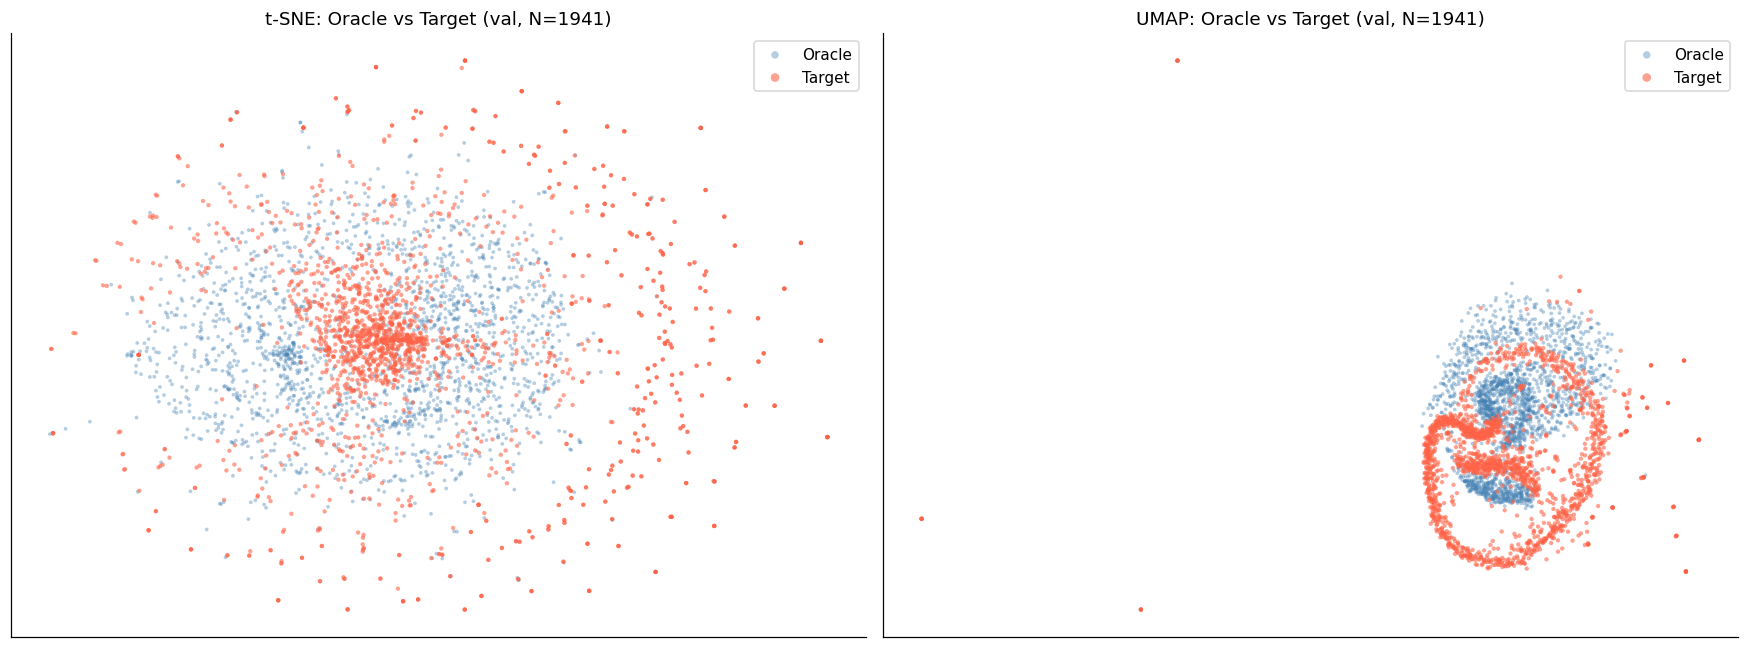

In [14]:
# ════════════════════════════════════════════════════════════
# t-SNE и UMAP
# ════════════════════════════════════════════════════════════
torch.manual_seed(SEED)
all_oracles, all_targets_emb = [], []
with torch.no_grad():
    for batch in loaders['val']:
        history, mask, target = (batch[k].to(device) for k in ('history', 'mask', 'target'))
        all_oracles.append(oracle_for(history, mask).cpu())
        all_targets_emb.append(model.item_embedding(target).cpu())

oracles = torch.cat(all_oracles).numpy()
targets = torch.cat(all_targets_emb).numpy()
N = len(oracles)
X = np.concatenate([oracles, targets], axis=0)
labels = np.array(['Oracle'] * N + ['Target'] * N)
print(f'Fitting on {2 * N} vectors ({N} oracle + {N} target), d={X.shape[1]}')

from sklearn.manifold import TSNE
X_tsne = TSNE(n_components=2, perplexity=40, random_state=SEED, n_jobs=-1).fit_transform(X)
print('t-SNE done')

try:
    import umap
    X_umap   = umap.UMAP(n_components=2, random_state=SEED).fit_transform(X)
    has_umap = True
    print('UMAP done')
except ImportError:
    has_umap = False
    print('UMAP not installed (pip install umap-learn). Showing only t-SNE.')

panels = [('t-SNE', X_tsne)] + ([('UMAP', X_umap)] if has_umap else [])
fig, axes = plt.subplots(1, len(panels), figsize=(8 * len(panels), 6), squeeze=False)
style = {'Oracle': ('steelblue', 0.4, 6), 'Target': ('tomato', 0.6, 8)}
for ax, (title, X_2d) in zip(axes[0], panels):
    for label, (color, alpha, size) in style.items():
        m = labels == label
        ax.scatter(X_2d[m, 0], X_2d[m, 1], c=color, alpha=alpha, s=size, label=label, edgecolors='none')
    ax.set_title(f'{title}: Oracle vs Target (val, N={N})', fontsize=12)
    ax.legend(fontsize=10, markerscale=2)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()